## Activity 2.1

### Load the generated data into PostgreSQL in a new table called orders. Write the CREATE TABLE yourself (choose sensible types for each column) and use the same \COPY pattern as in section 3.3.

In [ ]:
DROP TABLE IF EXISTS orders;

CREATE TABLE orders (
    id SERIAL PRIMARY KEY,
    customer_name TEXT,
    product_category TEXT,
    quantity INTEGER,
    price_per_unit NUMERIC(10, 2),
    order_date DATE,
    country TEXT
);

\COPY orders(customer_name,product_category,quantity,price_per_unit,order_date,country) FROM '/data/orders_1M.csv' DELIMITER ',' CSV HEADER;

### A. Which order has the highest price_per_unit?

In [ ]:
SELECT customer_name, product_category, price_per_unit, country, order_date
FROM orders
ORDER BY price_per_unit DESC
LIMIT 1;

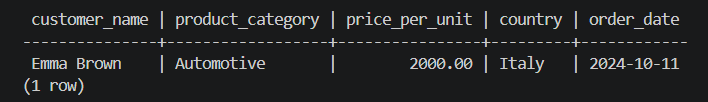

### B. What are the top 3 product categories with the highest total quantity sold across all orders?

In [ ]:
SELECT product_category, SUM(quantity) AS total_quantity
FROM orders
GROUP BY product_category
ORDER BY total_quantity DESC
LIMIT 3;

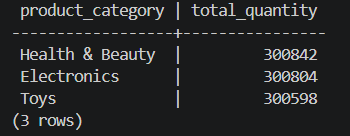

### C. What is the total revenue per product category? (Revenue = price_per_unit × quantity)

In [ ]:
SELECT product_category, SUM(price_per_unit * quantity) AS total_revenue
FROM orders
GROUP BY product_category
ORDER BY total_revenue DESC;

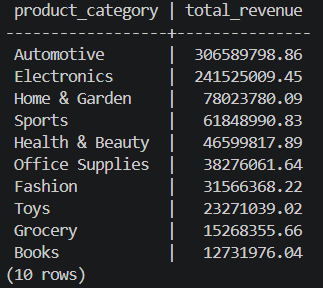

### D. Who are the top 5 customers by total spending?

In [ ]:
SELECT customer_name, SUM(price_per_unit * quantity) AS total_spending, COUNT(*) AS order_count
FROM orders
GROUP BY customer_name
ORDER BY total_spending DESC
LIMIT 5;

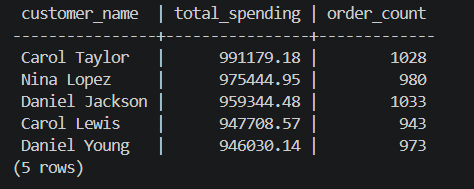

### E. Look at the spending totals in D — and at how many orders each of those customers has. What do you notice? Open ecommerce/dataset_generator.py and explain why the data looks like this.

When looking at the results of query D (top 5 customers by total spending), we can see that the top customers have an extraordinarily high number of orders ( roughly 950-1030) which results in massive spending totals that are unrealistically high for a single individual.

If we examine the dataset_generator.py file, we can see that:
- The script defines a very limited list of options, containing only 32 first names and 33 last names.
- This creates a total pool of only 32 x 33 = 1056 possible unique full-name combinations.
- The script generates 1 million rows and picks names randomly with replacement. Because there are only 1,056 possible names for 1 million rows, severe name collisions occur. Each generated "customer name" does not represent a single unique person. Instead it acts as a bucket aggregating thousands of completely unrelated transactions made by different buyers who happen to share the exact same randomly chosen name.

## Activity 2.2


| rows in table | join result (COUNT(*)) | time |
| :--- | :---: | ---: |
| 50 000 | 27 501 822 | 00:06.782 |
| 100 000 | 109 946 508 | 00:24.342 |
| 200 000 | 439 395 606 | 03:20.869 |

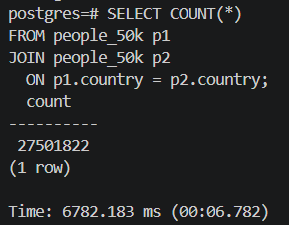    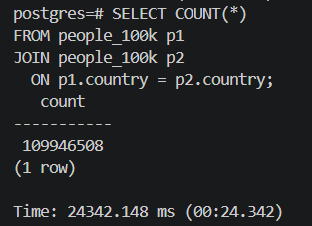    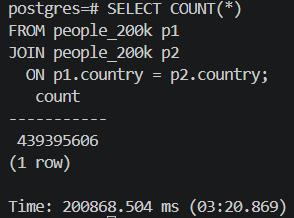

#### When the input doubles, by what factor do the result and the time grow? Use this to predict the result size and the runtime on people_big (1M rows).


Input 50 000 -> 100 000:
- Result Growth: around 4x
- Time Growth: around 3.6x

Input 100 000 -> 200 000:
- Result Growth: around 4x
- Time Growth: around 8.2x

Because doubling the input rows(x2) results in multiplying the output rows by 4(x4), the result size grows quadratically (O(N^2))

The time grew faster than quadratic between 100k and and 200k (8.2x instead of 4x). The query plan shows no spilling to disk('Batches: 1'), so this is most likely measurement noise. The result size is exactly quadratic, so I will use a quadratic model for the runtime prediction.

Prediction:

- Result Size:

Since we have quadratic growth, and going from 200k to 1 million rows is a 5x increase in input size:

5^2 = 25

Therefore the result size for 1 million rows will be:

439 395 606 x 25 = 10 984 890 150 rows (nearly 11 billion matching pairs)

- Runtime:

If the time scaled strictly quadratically, 1 million rows would take around:

200.9 sec x 25 = 5 020 sec = 84 minutes (roughly 1.4 hours).

### Step 2 — Does an index help? Create an index on country of people_100k, run ANALYZE people_100k;, and repeat the query. Did the time change? Use EXPLAIN ANALYZE to support your answer. Why does (or doesn't) the index help?

In [ ]:
-- Creating an index on the country column of people_100k
CREATE INDEX idx_people_100k_country ON people_100k(country);

-- Updating query optimizer statistics
ANALYZE people_100k;

-- Running the self-join query again to see if the execution time improved
SELECT COUNT(*)
FROM people_100k p1
JOIN people_100k p2
  ON p1.country = p2.country;

-- Use EXPLAIN ANALYZE to see how PostgreSQL actually executed the query
EXPLAIN ANALYZE
SELECT COUNT(*)
FROM people_100k p1
JOIN people_100k p2
  ON p1.country = p2.country;

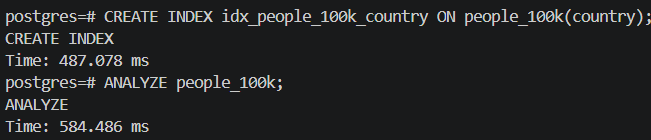  

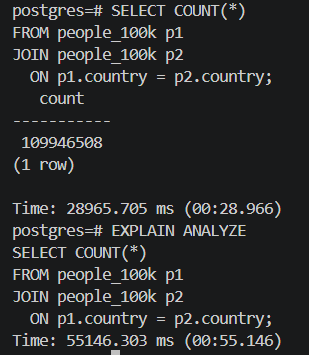

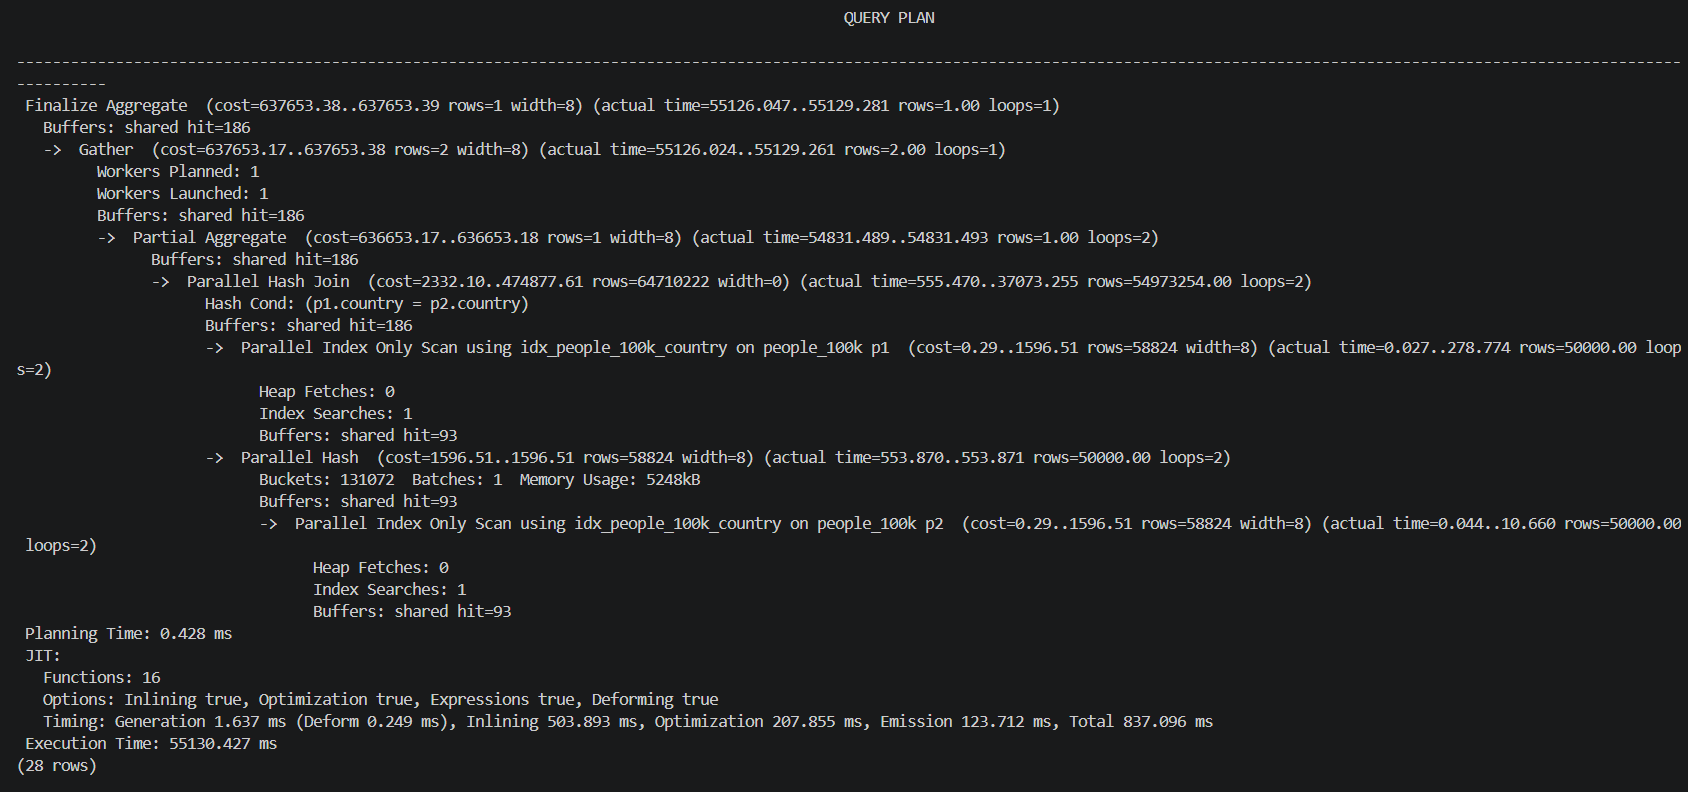

- Did the time change?

No. Before creating the index, the self-join query on people_100k took 24.34 seconds. After creating the index and running ANALYZE, the query took 28.97 seconds. The index did not speed up the query.

- Why does or doesn't the index help?

As shown in the EXPLAIN ANALYZE output, PostgreSQL did use the index via a Parallel Index Only Scan, allowing it to read the country values directly without touching table pages from disk.

However, the index didn't speed up the overall query because the bottleneck isnt retrieving the input data, but its combining it.

Even though the inputs were gathered quickly, PostgreSQL still had to perform a heavy Parallel Hash Join to pair every matching record together. An index only optimizes fetching and filtering input data. It cannot reduce the massive CPU cost required to process and count over 109 million matching join pairs. Ultimately, the quadratic growth of the join output dominates the total runtime, meaning it doesn't matter how fast we get the inputs if the final combination step remains massive.

### Step 3 — Rewrite it. The query only wants the number of matching pairs, not the pairs themselves. If a country has k people, how many pairs does it contribute to the join? Write a query that computes the same number without a join. Check that it returns exactly the same result as the join on people_100k, then run it on people_big and compare its runtime with your prediction from Step 1.

In [ ]:
-- Running the rewrite query on `people_100k` to verify it matches the join result
SELECT SUM(cnt * cnt) AS total_matching_pairs
FROM (
    SELECT country, COUNT(*) AS cnt
    FROM people_100k
    GROUP BY country
) sub;

-- Runnig the optimized rewrite query on the full 1M table (`people_big`)
SELECT SUM(cnt * cnt) AS total_matching_pairs
FROM (
    SELECT country, COUNT(*) AS cnt
    FROM people_big
    GROUP BY country
) sub;

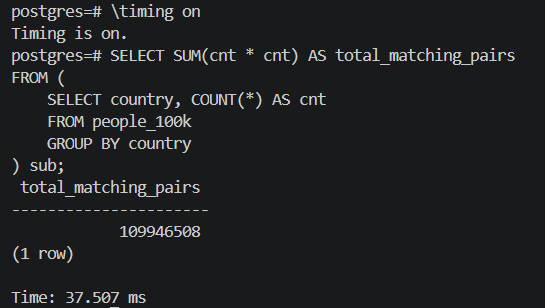

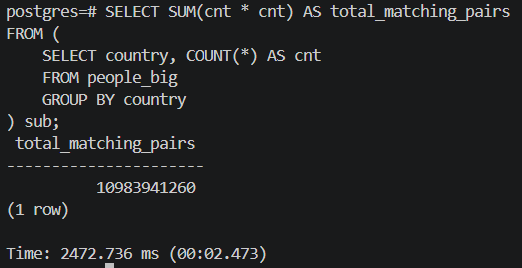

| Dataset / Method | Row Count | Query Time | Result (`total_matching_pairs`) |
| :--- | :--- | :--- | :--- |
| **`people_100k` (Self-Join from Step 1)** | 100,000 | **24,342 ms** (~24.3s) | 109,946,508 |
| **`people_100k` (Step 3 Rewrite)** | 100,000 | **37.507 ms** (~0.037s) | **109,946,508** |
| **`people_big` (Step 3 Rewrite)** | 1,000,000 | **2,472.736 ms** (~2.47s) | **10,983,941,260** |

If a country has k people, joining the table with itself produces k x k = k^2 matching pairs for that country. The self-join explicitly computes and outputs every single one of those pairs before counting them up.

The rewritten query avoids generating all k^2 pairs one by one. Instead, it groups the table by country, counts how many people are in each country (k), and then directly calculates k^2 (cnt * cnt) mathematically.   


From the table above we can see that on people_100k, the aggregation rewrite produces the exact same total matching count (109,946,508) as the self-join query.

The runtime plummeted from 24.34 seconds down to just 37.5 miliseconds, which is over 640x.

While the original self-join on 1 million rows would have taken roughly 84 minutes according to my quadratic prediction, the rewritten query processed all rows in just 2.47 seconds, yielding 10,983,941,260 total matching pairs which aligns almost perfectly with my earlier Step 1 prediction of approx. 10.98 billion.

### Step 4 — Discussion

Question 1: What does the rewrite in Step 3 tell us about hardware, indexes, and query design?

1. Algorithmic complexity surpasses hardware. The dramatic drop in execution time from 24 sec to just 37.5 ms, and running 1 million rows in 2.47 sec proves that no amount of faster CPUs or added memory can compensate for an O(N^2) algorithm.

2. Indexes cannot fix combinatorial expansion. Adding the index in step 2 did not improve performance because the bottleneck was not finding the data, but processing the 109+ million pairwise join combinations.

3. Scalability begins with query design. Changing the query pattern from an explosive self-join to a single-pass aggregation transformed the algorithmic complexity from quadratic O(N^2) to linear O(N), solving in milliseconds what hardware alone could not.

Question 2: What if the business actually needs the individual pairs, not just the total count?

If the business requirement demands returning every matching pair of IDs, we can no longer bypass the join via aggregation (cnt * cnt). Generating billions of output rows creates severe resource constraints:

- Vertical Scaling (Bigger Server): Increasing RAM and CPU on a single machine provides limited relief. It allows a larger in-memory hash table, but it eventually fails when the intermediate result set (nearly 11 billion rows for 1M inputs) exceeds available memory and disk storage.   

- Horizontal Scaling (Distributed Computing): To output billions of join pairs, the workload must be moved out of a single relational database and distributed across a cluster using frameworks like Apache Spark, Trino/Presto, or distributed cloud data warehouses (Snowflake, Google BigQuery). These platforms partition the data across multiple worker nodes to execute distributed shuffle joins in parallel.

Question 3: What are the risks of running this type of analytical workload on an OLTP database in a cloud environment?

1. Resource Exhaustion: OLTP databases like PostgreSQL are optimized for short, concurrent transactions (e.g., INSERT, UPDATE, point lookups). Running an O(N^2) join forces CPU utilization to 100% and saturates disk I/O, evicting cached transactional data from the buffer pool and causing severe latency spikes for live application users.

2. Cost Inefficiency in Cloud Infrastructure: Over-provisioning a cloud database instance (e.g., AWS RDS) with massive CPU and RAM just to support occasional analytical cross-joins is extremely expensive.

3. Best Practice Architecture: The standard cloud pattern is to keep the OLTP database lean for operational traffic and stream/replicate data (via CDC or ETL) into an OLAP system built for columnar storage and massive parallel analytics.
